# Fig. 8 · AL 阶梯回放：同一架构，只换训练数据

**主张**：8 代主动学习数据集（gen0–gen9 + 部署版 prod_train）各自训练一个 MACE 并完整评估。分数随代数非单调，帧数解释不了质量；所有代都卡在 L1 的二体 PEC 检查上，且不随数据增多而改善——委员会不确定性采样不会主动去 MD 很少访问的构型，评估则能指出这个缺口。

- **a** 总分随代数（相对分，8 个模型之间）；gen4 为 off-path 数据，gen8 为剪枝后数据。
- **b** 总分 vs 训练帧数。
- **c** 分层得分热图。
- **d** L0 力 MAE；**e** L2 EOS B₀ 误差（该系列无应力标签，B₀ 为外推）；**f** L1 门控逐项。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig8_al_ladder"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25          # notebook 内预览缩放；不影响导出
LEFT, RIGHT, WS = 0.135, 0.985, 0.42    # copied verbatim by every 3-column figure
CH, G, BM, TM = 1.45, 0.62, 0.36, 0.24  # row height, row gap, bottom/top margin (in)
ROWS = 2
LETTERS = "abcdef"

def make_layout():
    H = BM + ROWS * CH + (ROWS - 1) * G + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(ROWS, 3, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          wspace=WS, hspace=G / CH)
    slots = {}
    for i, letter in enumerate(LETTERS):
        r, c = divmod(i, 3)
        slots[letter] = gs[r, c]
    return fig, Slots(slots)

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

In [4]:
RL = ranking(AL_LADDER, clean=True)
ROWL = {r.indicator.key: r for r in RL.rows}
X = np.arange(len(AL_LADDER))
print({AL_SHORT[k]: round(RL.overall[k], 1) for k in AL_LADDER})

{'gen0': 55.7, 'gen3': 71.1, 'gen4': 77.3, 'gen6': 66.1, 'gen7': 73.6, 'gen8': 58.4, 'gen9': 66.2, 'prod': 85.1}


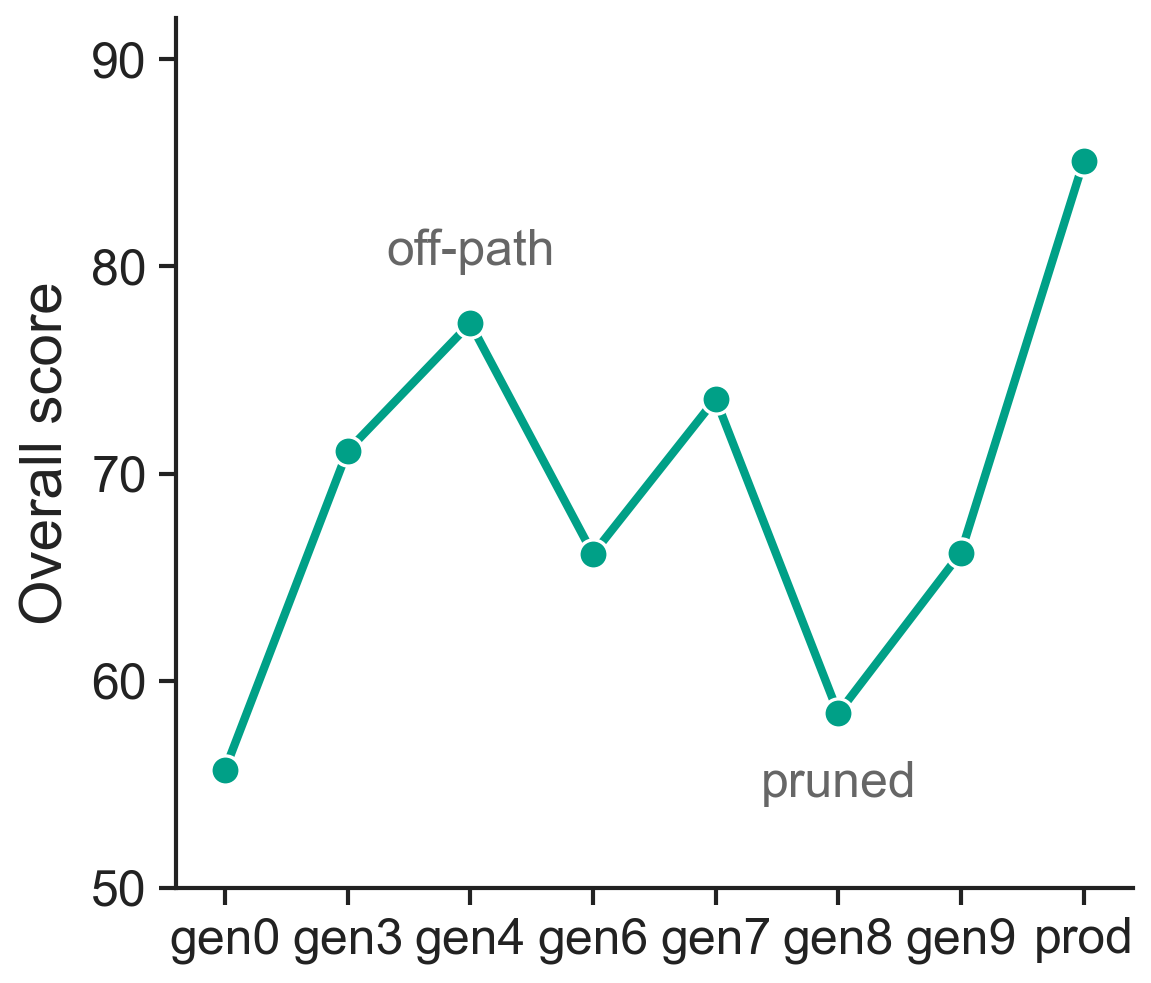

In [5]:
# ---------------- 本面板配色 ----------------
Ca_LINE = "#00A087"
Ca_NOTE = "#666666"
# --------------------------------------------
def gen_axis(ax):
    ax.set_xticks(X); ax.set_xticklabels([AL_SHORT[k] for k in AL_LADDER]); ax.set_xlim(-0.4, len(X) - 0.6)
def draw_a(fig, spec):
    ax = fig.add_subplot(spec)
    v = [RL.overall[k] for k in AL_LADDER]
    ax.plot(X, v, color=Ca_LINE, lw=1.0, marker="o", ms=3.5, mec="white", mew=0.4)
    for k, txt in (("al_gen4", "off-path"), ("al_gen8", "pruned")):
        i = AL_LADDER.index(k)
        ax.annotate(txt, (i, RL.overall[k]), xytext=(0, 7 if k == "al_gen4" else -10), textcoords="offset points",
                    ha="center", fontsize=FS_ANNOT, color=Ca_NOTE)
    gen_axis(ax); ax.set_ylim(50, 92); ax.set_ylabel("Overall score")
    return ax
panel_run("a", draw_a)

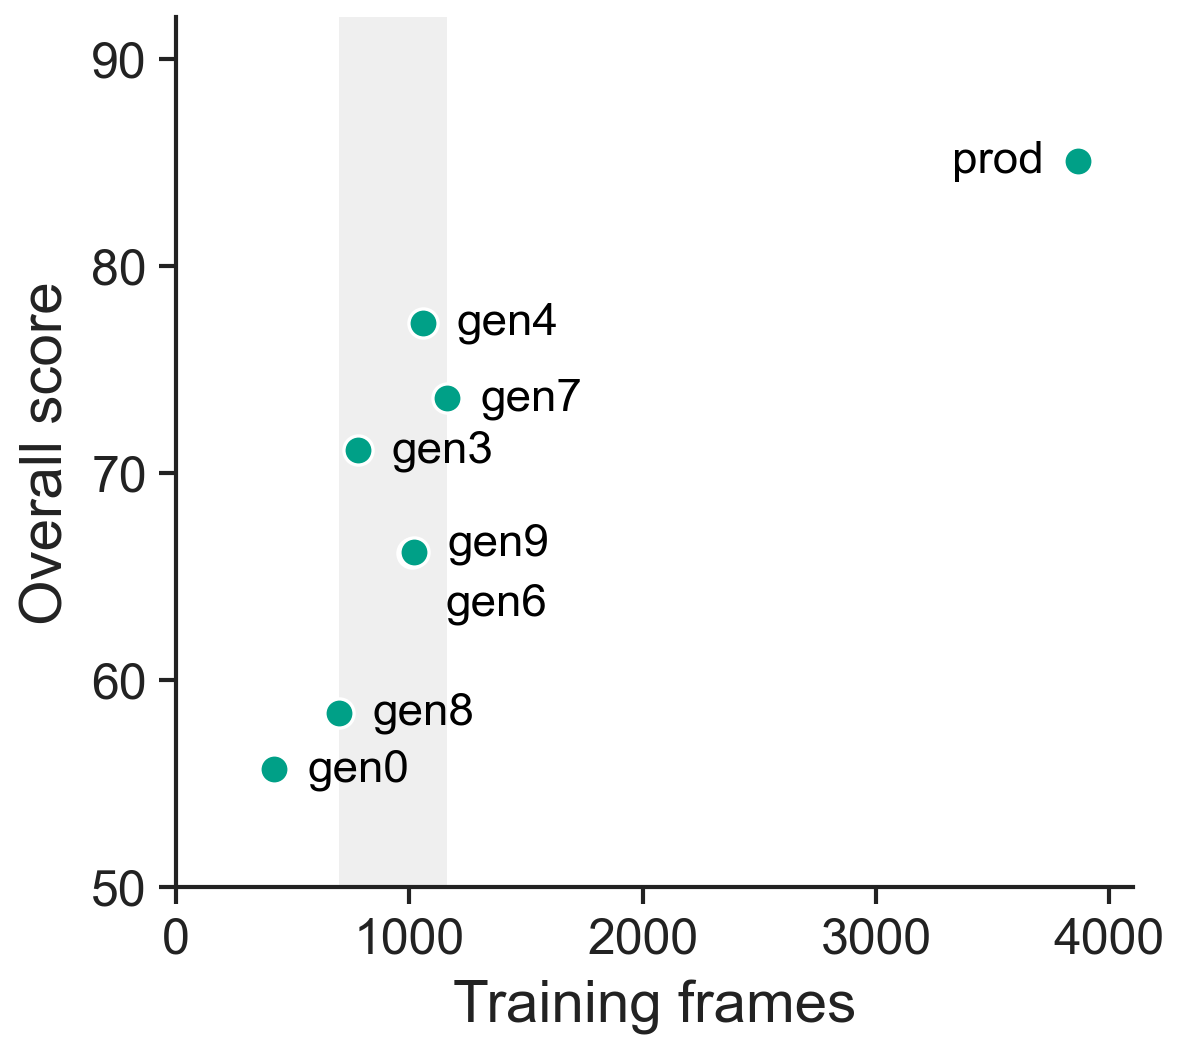

In [6]:
# ---------------- 本面板配色 ----------------
Cb_DOT = "#00A087"
Cb_BAND = "#EFEFEF"
# --------------------------------------------
def draw_b(fig, spec):
    ax = fig.add_subplot(spec)
    ax.axvspan(700, 1161, color=Cb_BAND, lw=0)
    for k in AL_LADDER:
        ax.plot(AL_FRAMES[k], RL.overall[k], "o", color=Cb_DOT, ms=3.5, mec="white", mew=0.4)
        dx, dy, ha = {"al_prod": (-4, 0, "right"), "al_gen6": (4, -6, "left"), "al_gen9": (4, 1, "left")}.get(k, (4, 0, "left"))
        ax.annotate(AL_SHORT[k], (AL_FRAMES[k], RL.overall[k]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=FS_ANNOT - 0.5, va="center", ha=ha)
    ax.set_xlim(0, 4100); ax.set_ylim(50, 92)
    ax.set_xlabel("Training frames"); ax.set_ylabel("Overall score")
    return ax
panel_run("b", draw_b)

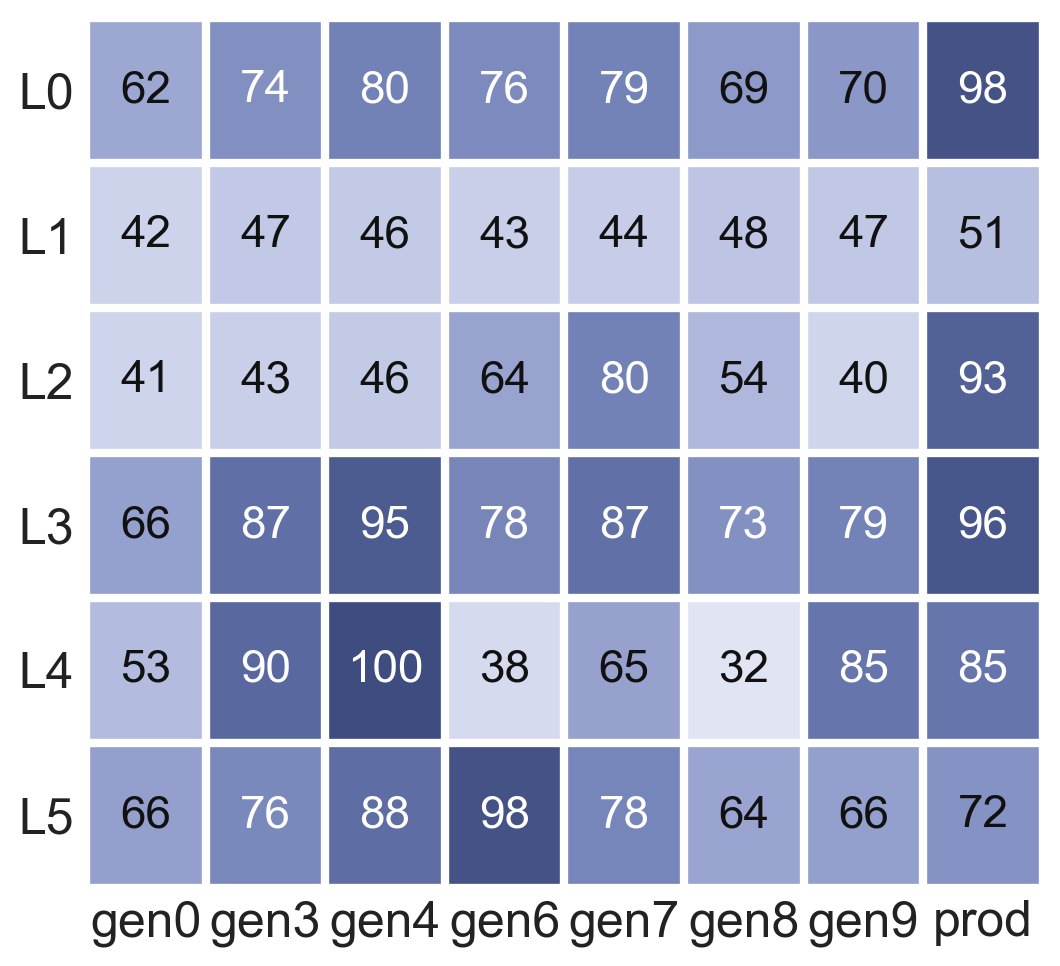

In [7]:
# ---------------- 本面板配色 ----------------
from matplotlib.colors import LinearSegmentedColormap
Cc_CMAP = LinearSegmentedColormap.from_list("score", ["#F7F8FC", "#DEE2F2", "#C2C9E6", "#A2ACD6", "#8290C2", "#6373AA", "#3E4C80"])
# --------------------------------------------
def draw_c(fig, spec):
    ax = fig.add_subplot(spec)
    M = np.array([[RL.level_scores[lv][k] if RL.level_scores[lv][k] is not None else np.nan for k in AL_LADDER] for lv in LEVELS])
    ax.imshow(M, cmap=Cc_CMAP, vmin=20, vmax=100, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=FS_ANNOT - 0.5,
                    color="#FFFFFF" if M[i, j] > 72 else "#111111")
    ax.set_xticks(X); ax.set_xticklabels([AL_SHORT[k] for k in AL_LADDER], rotation=0)
    ax.set_yticks(range(len(LEVELS))); ax.set_yticklabels(LEVELS)
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(X)), minor=True); ax.set_yticks(np.arange(-0.5, len(LEVELS)), minor=True)
    ax.grid(which="minor", color="#FFFFFF", lw=1.0); ax.tick_params(which="minor", length=0)
    return ax
panel_run("c", draw_c)

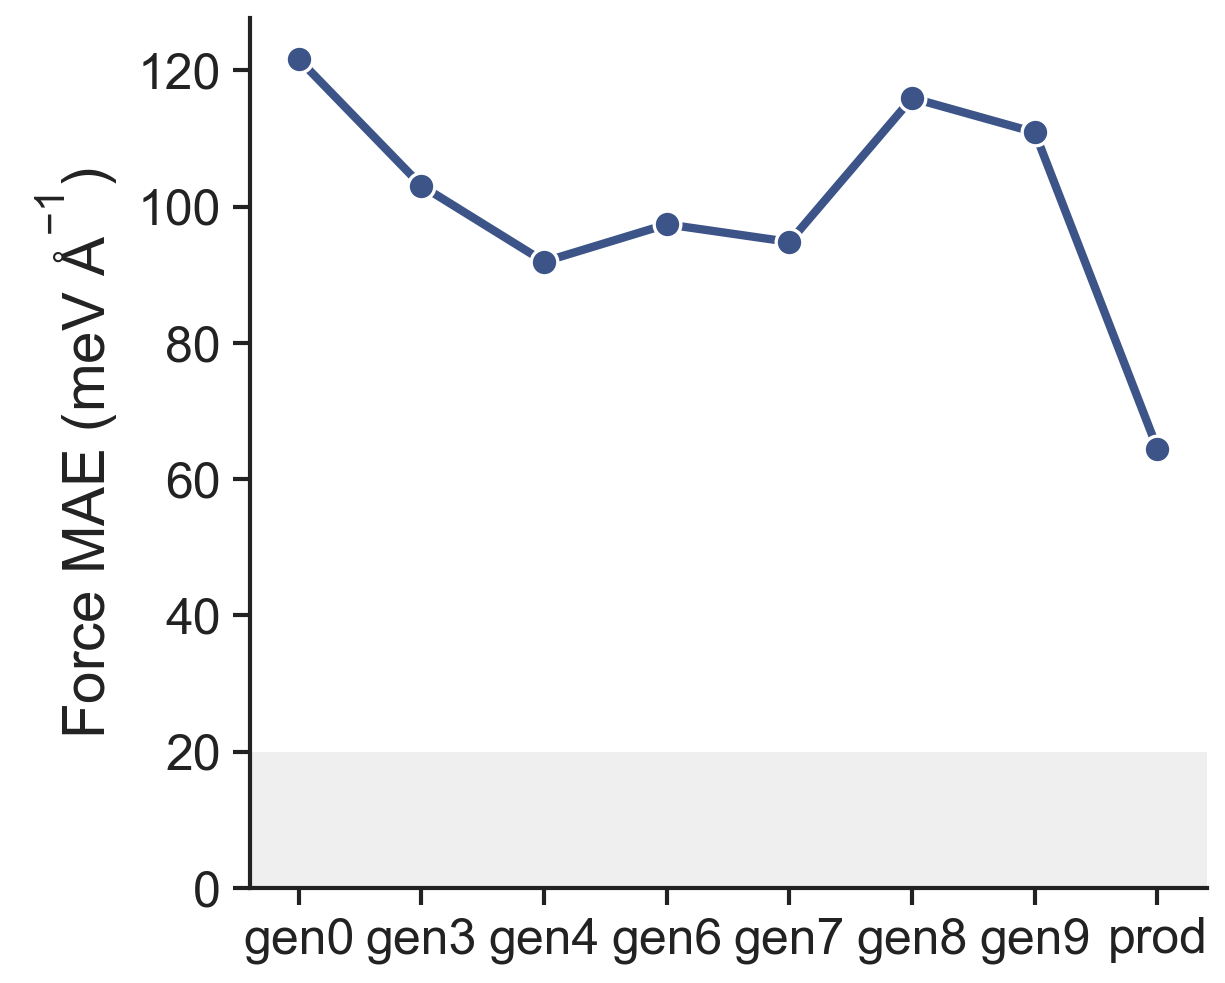

In [8]:
# ---------------- 本面板配色 ----------------
Cd_LINE = "#3C5488"
# --------------------------------------------
def raw_line(fig, spec, key, ylabel, scale, color):
    ax = fig.add_subplot(spec)
    row = ROWL[key]
    v = [row.raw[k] * scale if row.raw.get(k) is not None else np.nan for k in AL_LADDER]
    ax.axhspan(0, row.indicator.floor * scale, color="#EFEFEF", lw=0)
    ax.plot(X, v, color=color, lw=1.0, marker="o", ms=3.2, mec="white", mew=0.4)
    gen_axis(ax); ax.set_ylabel(ylabel); ax.set_ylim(bottom=0)
    return ax
def draw_d(fig, spec):
    return raw_line(fig, spec, "force MAE", "Force MAE (meV Å$^{-1}$)", 1000, Cd_LINE)
panel_run("d", draw_d)

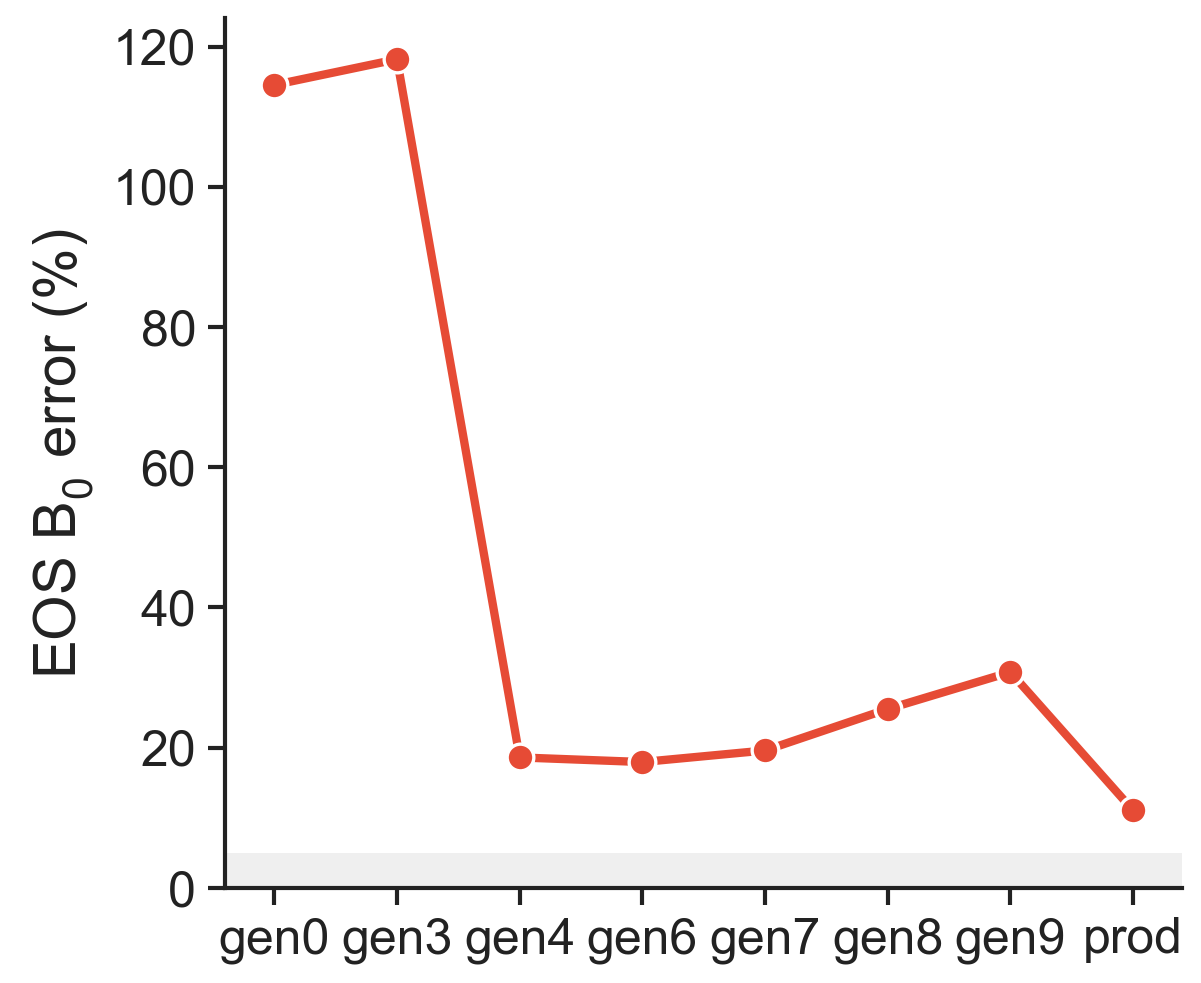

In [9]:
# ---------------- 本面板配色 ----------------
Ce_LINE = "#E64B35"
# --------------------------------------------
def draw_e(fig, spec):
    return raw_line(fig, spec, "EOS B0 error", "EOS B$_0$ error (%)", 1, Ce_LINE)
panel_run("e", draw_e)

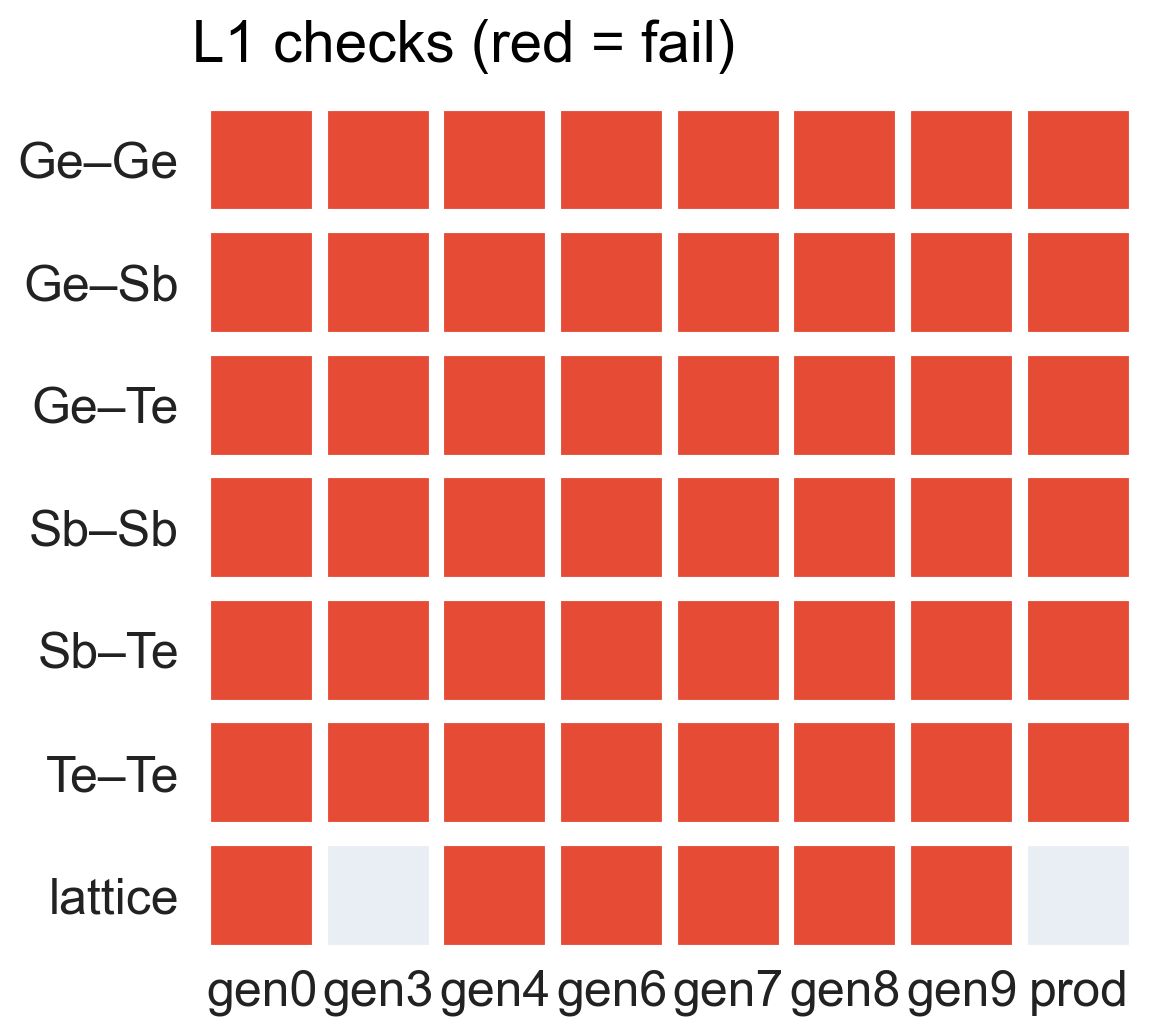

In [10]:
# ---------------- 本面板配色 ----------------
Cf_PASS, Cf_FAIL = "#E9EEF5", "#E64B35"
COLS = [f"L1.pec.{p}" for p in ["Ge-Ge", "Ge-Sb", "Ge-Te", "Sb-Sb", "Sb-Te", "Te-Te"]] + ["L1.lattice_scan_smoothness"]
COL_NAMES = ["Ge–Ge", "Ge–Sb", "Ge–Te", "Sb–Sb", "Sb–Te", "Te–Te", "lattice"]
# --------------------------------------------
def draw_f(fig, spec):
    ax = fig.add_subplot(spec)
    from matplotlib.patches import Rectangle
    for i, k in enumerate(AL_LADDER):
        failed = set(gate_failed(k))
        for j, m in enumerate(COLS):
            ax.add_patch(Rectangle((i - 0.45, j - 0.42), 0.9, 0.84, facecolor=Cf_FAIL if m in failed else Cf_PASS,
                                   edgecolor="#FFFFFF", lw=0.5))
    ax.set_xlim(-0.6, len(AL_LADDER) - 0.4); ax.set_ylim(len(COLS) - 0.5, -0.6)
    ax.set_xticks(X); ax.set_xticklabels([AL_SHORT[k] for k in AL_LADDER])
    ax.set_yticks(range(len(COLS))); ax.set_yticklabels(COL_NAMES)
    ax.tick_params(length=0)
    for s in ("bottom", "left"): ax.spines[s].set_visible(False)
    ax.set_title("L1 checks (red = fail)", loc="left")
    return ax
panel_run("f", draw_f)

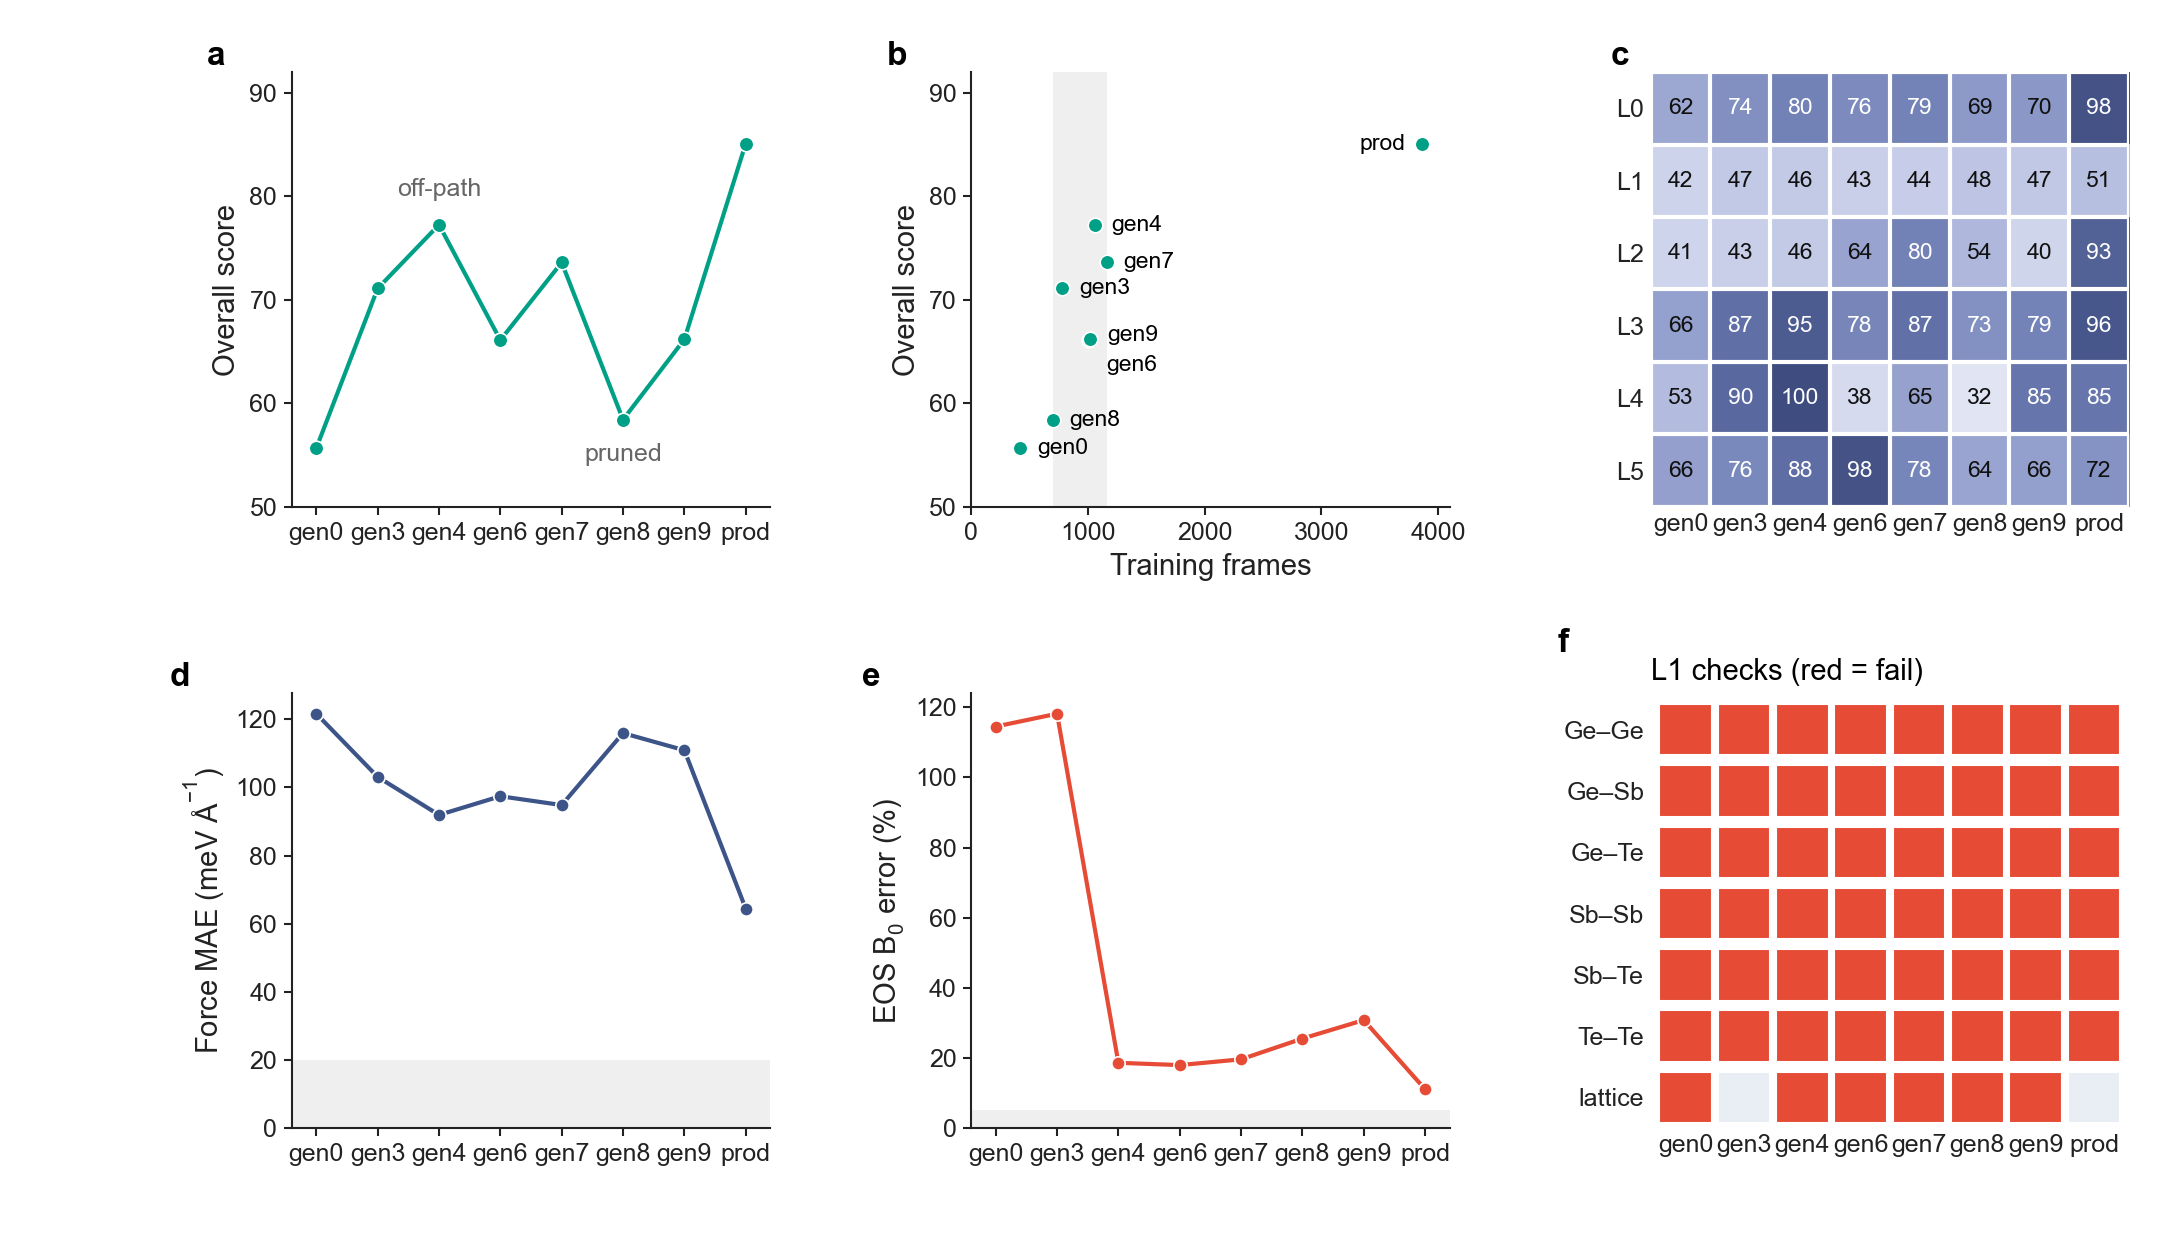

In [11]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig8_al_ladder")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))